# 03 Estimation (layer 3)

Layer 3 turns the calibrated flood map from layer 2 plus a few field checks into, for every insurance
unit u (village or panchayat):

* `theta_u`, the estimated flooded share of the unit's paddy area, with a standard error `s_u`;
* the **always-answered call** `[theta_u > 0.25]`, with `P_u = Phi((theta_u - 0.25) / s_u)`, the
  probability that the unit is truly above the line. There is no abstain or "insufficient evidence" state;
  a weak call shows up as `P_u` near 0.5;
* a **flip value** for farmer reports: how biased the reports would have to be before trusting them would
  flip the call.

Steps
1. Inputs: real layer 1 and 2 artifacts if present, otherwise the documented synthetic generator in
   `paddybird.estimator.synthetic_pixels`.
2. Stratify plots by calibrated score and fit the few hyperparameters on the **training region only**.
3. Estimator: stratified, shrunk, prediction-powered (map plus measured map error), importance-weighted
   with KNOWN inclusion probabilities, cluster-robust variance over visit sites.
4. Calls, `P_u`, flip value.
5. Validation on a held-out validation region: Monte Carlo over many random check draws; bias, RMSE,
   interval coverage, wrong calls, calibration of `P_u`, against map-only and sample-only baselines.
6. Stress test: route-style (near-road) selection, with and without the inclusion probabilities.
7. **Test region, touched once**, then artifacts and the closing assertion.

**No overfitting.** Strata cut points are fixed in advance (0.15 and 0.6 on the calibrated probability).
The pooled map correction, its between-unit covariance, the within-site correlation and the prior strength
`m` are fitted on the training region. The validation region is used to look at the methods; nothing is
tuned on it. The test region is a different region (different seed and a different flood level) and is
scored once, in the marked cell near the end. Every random draw has a fixed seed.

In [1]:
import hashlib, json, pathlib, platform, sys, time, csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "paddybird").exists():
    ROOT = ROOT / "notebooks"
sys.path.insert(0, str(ROOT))
from paddybird import estimator as E, calls as K, variance as V

ART = ROOT / "artifacts"
OUT = ART / "layer3"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 20261118
TAU = 0.25
K_VISIT = 4                       # plots checked per visit site
BUDGETS = [0, 4, 8, 16, 32, 64]   # mean field checks (plots) per unit
B_SHOW = 16                       # budget used for the single-draw figures and the reliability curve
REPS_VAL, REPS_TEST = 120, 200    # Monte Carlo check draws per budget
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def sha(p):
    try:
        return hashlib.sha256(pathlib.Path(p).read_bytes()).hexdigest()[:16]
    except OSError:
        return "missing"
print("python", platform.python_version(), " numpy", np.__version__, " matplotlib", matplotlib.__version__)

python 3.11.9  numpy 2.4.6  matplotlib 3.11.2


## 1. Inputs

The contract between layers is files. If `artifacts/layer2/` holds per-pixel calibrated probabilities with
labels and an event split (and `artifacts/layer1/` optionally holds chip-window units), the notebook uses
them: units are the layer 1 pseudo-villages, plots are 4 x 4 pixel blocks (80 m), visit sites are 16 x 16 blocks (320 m),
and the split is by event. Otherwise it falls back to the synthetic stand-in, three regions generated with
different seeds: train (six flood events; the map calibration and every hyperparameter are fitted here),
validation and test (one new event each, with its own flood level and map bias, so the training
correction does not transfer perfectly, as with a real new event).

Synthetic world (see `synthetic_pixels`): unit -> 10 to 22 visit sites -> 12 to 35 plots -> 16 to 80 pixels.
True flooding has unit, site and plot effects (neighbouring plots flood together). The map has a unit-level
bias, a site-level bias, and near motorable roads plots sit higher (less flooded) while the map sees them as
wetter. That last effect is what makes route-style checks biased.

In [2]:
chips, src2 = E.load_layer2_chips(ART)
units1 = E.load_layer1_units(ART) if chips is not None else None
frames = E.frames_from_chips(chips, units1) if chips is not None else None
if frames is not None and all(frames.get(k) is not None for k in ("train", "test")):
    INPUT = "real layer 2 artifacts (" + src2 + "; units: " + frames["unit_source"] + ")"
    tr, te = frames["train"], frames["test"]
    va = frames["val"] if frames["val"] is not None else frames["test"]
    SRC_HASH = {pathlib.Path(c["path"]).name: sha(c["path"]) for c in chips}
    SRC_HASH["layer2/MANIFEST.json"] = sha(ART / "layer2" / "MANIFEST.json")
else:
    INPUT = "synthetic stand-in (" + (src2 if chips is None else "layer 2 file lacks train and test") + ")"
    px_tr = E.synthetic_pixels(120, seed=SEED + 1, n_events=6)   # training region = 6 flood events
    calib = px_tr["calib"]                     # Platt calibration fitted on the training region only
    def mk(px):
        return E.frame_from_pixels(px["unit"], px["plot"], px["prob"], px["site"], px["label"], px["road_km"], event=px["event"])
    tr = mk(px_tr)
    va = mk(E.synthetic_pixels(120, seed=SEED + 2, flood_shift=0.3, calib=calib))
    te = mk(E.synthetic_pixels(120, seed=SEED + 3, flood_shift=0.15, calib=calib))
    SRC_HASH = {}
    for nm, fr in (("TR", tr), ("VA", va), ("TE", te)):
        fr.unit_ids = np.array([f"SYN-{nm}-{i:03d}" for i in range(fr.U)])
    del px_tr
print("input:", INPUT)
for name, fr in (("train", tr), ("val", va), ("test", te)):
    print(f"{name:5s} units {fr.U:4d}  plots {fr.n_plots:6d}  sites {fr.S:5d}  mean share {fr.theta_true.mean():.3f}"
          f"  units above 25%: {(fr.theta_true > TAU).mean():.2f}  map minus truth: {np.mean(fr.theta_map - fr.theta_true):+.3f}")

input: real layer 2 artifacts (artifacts/layer2/maps (121 chips); units: layer 1 chip windows (121 chips))
train units  125  plots  23071  sites  1885  mean share 0.114  units above 25%: 0.14  map minus truth: +0.080
val   units   27  plots   4704  sites   410  mean share 0.133  units above 25%: 0.19  map minus truth: +0.009
test  units   34  plots   6862  sites   528  mean share 0.208  units above 25%: 0.26  map minus truth: -0.077


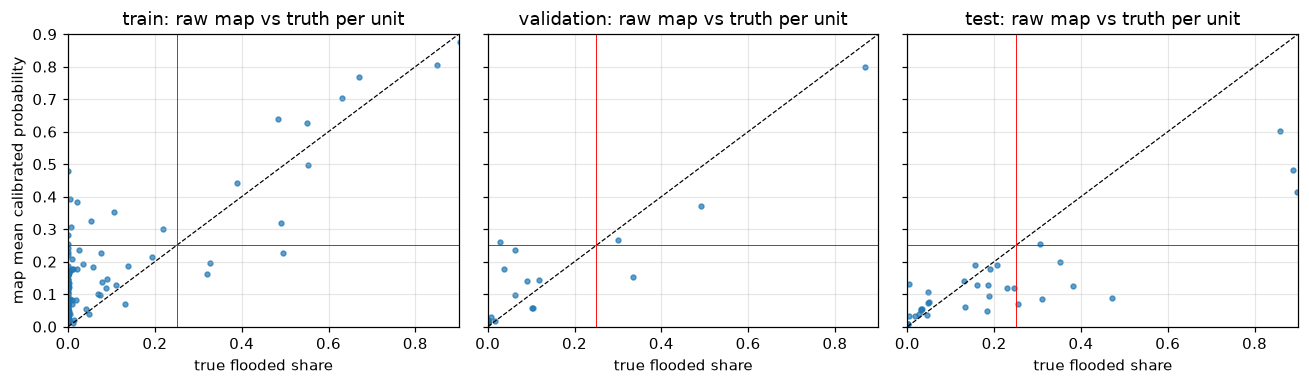

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for a, (name, fr) in zip(ax, (("train", tr), ("validation", va), ("test", te))):
    a.scatter(fr.theta_true, fr.theta_map, s=10, alpha=.7)
    a.plot([0, 1], [0, 1], "k--", lw=.8); a.axhline(TAU, color="r", lw=.6); a.axvline(TAU, color="r", lw=.6)
    a.set_title(f"{name}: raw map vs truth per unit"); a.set_xlabel("true flooded share")
ax[0].set_ylabel("map mean calibrated probability"); ax[0].set_xlim(0, .9); ax[0].set_ylim(0, .9)
fig.tight_layout(); fig.savefig(OUT / "fig_inputs.png", dpi=130); plt.show()

## 2. Stratify and fit on the training region

Strata come from the calibrated score: mapped dry (f < 0.15), uncertain (0.15 to 0.6), mapped flooded
(f >= 0.6). Inside each unit-stratum the estimator measures the map error (the rectifier `e = y - f`).
From the training region we fit:

* `Rpool_h`, the training-region rectifier per stratum (the prior for a unit with no checks);
* `T`, the between-unit covariance of the stratum rectifiers around their own event's pool (how far one
  unit's map error can sit from its event; this is the error of a shrunk estimate);
* `T_ev`, the between-event covariance of the event pools around `Rpool` (how far a NEW event's map
  error can sit from the training pool);
* the within-stratum plot variance and the intra-site correlation (ICC) of the rectifier, which give the
  design effect `1 + (k - 1) ICC` of checking `k` neighbouring plots per visit;
* the prior strength `m`, by a grid search over random check draws **on the training region**.

fitted in 0.5 s
strata cuts (0.15, 0.6)  Rpool [-0.035 -0.207 -0.14 ]  pi_h [0.009 0.102 0.768]
sd of unit rectifier per stratum [0.044 0.174 0.285]  sd of event pool (7 training events) [0.02  0.15  0.306]
ICC 0.33 -> design effect 2.00 for 4 plots per site;  chosen m = 1.0
training-region RMSE by m: {'0.5': 0.0576, '1': 0.0568, '2': 0.0569, '4': 0.0588, '8': 0.0622, '16': 0.066, '32': 0.0692}


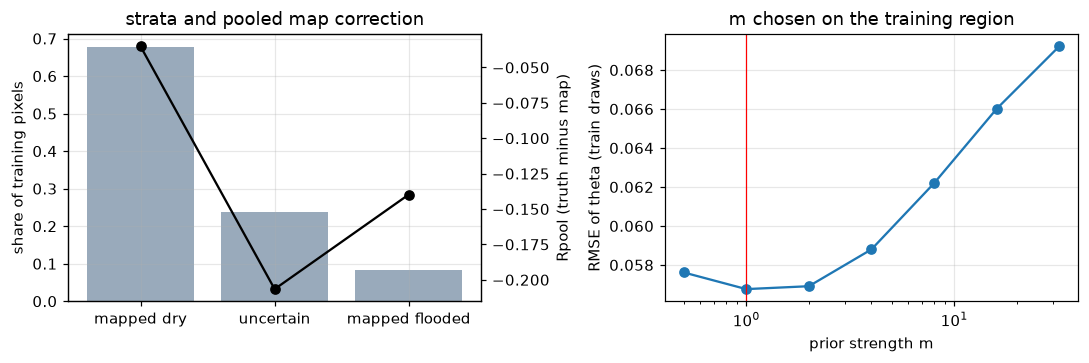

In [4]:
t0 = time.time()
hyp = E.fit_hyper(tr, k=K_VISIT, seed=SEED)
print(f"fitted in {time.time() - t0:.1f} s")
print("strata cuts", hyp.cuts, " Rpool", np.round(hyp.Rpool, 3), " pi_h", np.round(hyp.pi_h, 3))
print("sd of unit rectifier per stratum", np.round(np.sqrt(np.diag(hyp.T)), 3),
      f" sd of event pool ({hyp.n_events} training events)", np.round(np.sqrt(np.diag(hyp.t_ev())), 3))
print(f"ICC {hyp.icc:.2f} -> design effect {hyp.deff:.2f} for {hyp.k} plots per site;  chosen m = {hyp.m}")
print("training-region RMSE by m:", {k: round(v, 4) for k, v in hyp.m_grid_rmse.items()})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
share = [np.sum(tr.w[tr.h == j]) / tr.w.sum() for j in range(tr.H)]
lab = ["mapped dry", "uncertain", "mapped flooded"]
ax[0].bar(lab, share, color="#9ab"); ax[0].set_ylabel("share of training pixels")
ax2 = ax[0].twinx(); ax2.plot(lab, hyp.Rpool, "ko-"); ax2.set_ylabel("Rpool (truth minus map)"); ax2.grid(False)
ax[0].set_title("strata and pooled map correction")
mm = [float(k) for k in hyp.m_grid_rmse]; ax[1].semilogx(mm, list(hyp.m_grid_rmse.values()), "o-")
ax[1].axvline(hyp.m, color="r", lw=.8); ax[1].set_xlabel("prior strength m"); ax[1].set_ylabel("RMSE of theta (train draws)")
ax[1].set_title("m chosen on the training region")
fig.tight_layout(); fig.savefig(OUT / "fig_strata_fit.png", dpi=130); plt.show()

## 3. The estimator on one draw of checks

For unit u and stratum h, with checked plots c carrying KNOWN inclusion probabilities `pi_c` and
`d_c = 1 / pi_c`:

    R_uh    = sum d_c w_c (y_c - f_c) / sum d_c w_c          (Hajek, importance-weighted)
    lam_uh  = n_eff / (n_eff + m)
    P_h     = precision-weighted mix of Rpool_h (variance T_ev) and the importance-weighted
              pooled rectifier of all checks in this region (cluster-robust over units)
    theta_u = sum_h W_uh (Fbar_uh + lam_uh R_uh + (1 - lam_uh) P_h)
    s_u^2   = V_cluster-robust(sites) + a' T a + sum_h a_h^2 Var(P_h),  a_h = W_uh (1 - lam_uh)

This is the prediction-powered form: the map supplies `Fbar_uh` for every plot, the checks only have to
measure the map's error, and that error has far less variance than the flooded share itself. The design
used here draws visit sites by Poisson sampling (expected `budget / 4` per unit) and 4 plots per site.

**Version history (honest record).** v1 shrank every unit toward the training pool `Rpool_h` and treated
that pool as exact. On its first and only clean test run (real layer 2 maps, held-out events Bolivia and
India) v1 missed its coverage bound: the India map under-reads flooding while the training events'
maps over-read it, so shrinking toward the training pool pulled every estimate down (90% interval
coverage 0.74 at 16 checks per unit). v2, used below, adds the between-event spread `T_ev` and lets the
pool be learnt from the region's own checks. v2 was written after seeing that test result and was
developed on the validation region only, but **its test numbers are therefore not a clean held-out
estimate**; the v1 numbers are kept in `test_first_run_v1.json` and printed in Section 7. `ppi_v1` stays
in every table for comparison.
The figure shows one draw at 16 checks per unit on the validation region.

checks drawn 399, units with at least one check 1.00, median visit sites per unit 4


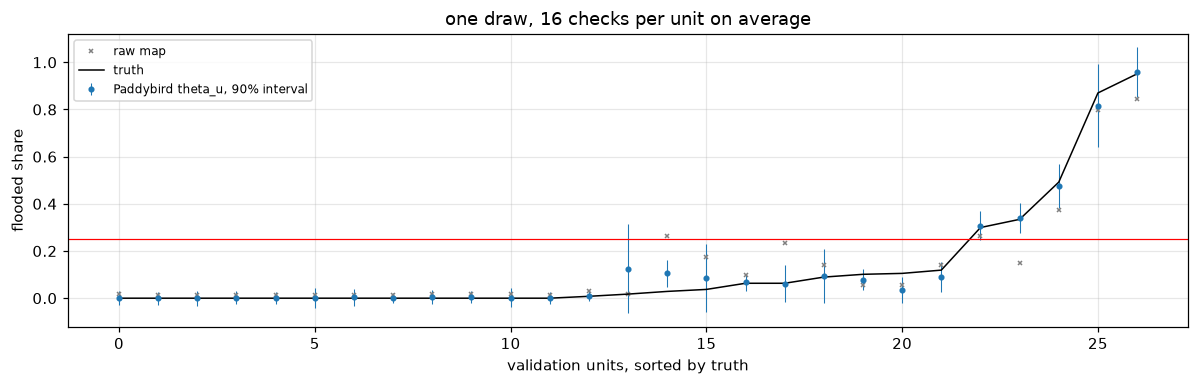

In [5]:
rng = np.random.default_rng([SEED, 3])
chk = E.draw_checks(va, B_SHOW, rng, "random", K_VISIT)
one = E.run_methods(va, chk, hyp)
ours = one["ppi_ipw"]
print(f"checks drawn {len(chk['idx'])}, units with at least one check {np.mean(ours['n'] > 0):.2f}, "
      f"median visit sites per unit {np.median(ours['n_sites']):.0f}")
order = np.argsort(va.theta_true)
fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(va.U)
ax.errorbar(x, ours["theta"][order], yerr=1.645 * ours["s"][order], fmt="o", ms=3, lw=.7, label="Paddybird theta_u, 90% interval")
ax.plot(x, va.theta_map[order], "x", ms=3, color="grey", label="raw map")
ax.plot(x, va.theta_true[order], "k-", lw=1, label="truth")
ax.axhline(TAU, color="r", lw=.8); ax.set_xlabel("validation units, sorted by truth"); ax.set_ylabel("flooded share")
ax.legend(fontsize=8); ax.set_title(f"one draw, {B_SHOW} checks per unit on average")
fig.tight_layout(); fig.savefig(OUT / "fig_one_draw.png", dpi=130); plt.show()

## 4. Calls, P_u and the farmer-report flip value

Every unit gets a call. `P_u` is the probability that the unit is truly above 0.25; `P_right` is the
probability that the stated call is right. Farmer reports are a separate, self-selected group and are
never mixed into `theta_u`. The flip value `b*` (see `calls.py`) says how far the reports would have to
overstate flooding before trusting them would put the combined estimate on the line.

The reports here are synthetic: a plot's farmer reports with probability `0.03 + 0.12 y_c` (flooded
farmers report more), and says "flooded" when more than half the plot is flooded, plus 10% false
"flooded" claims.

units with reports 1.00, median reports per unit 6
mean report share 0.245 vs mean true share 0.133  (true report bias +0.113)
wrong calls: official 0.000; reports taken at face value 0.000
units where trusting the reports would flip the call: 0; median |b*| there nan, elsewhere 5.304


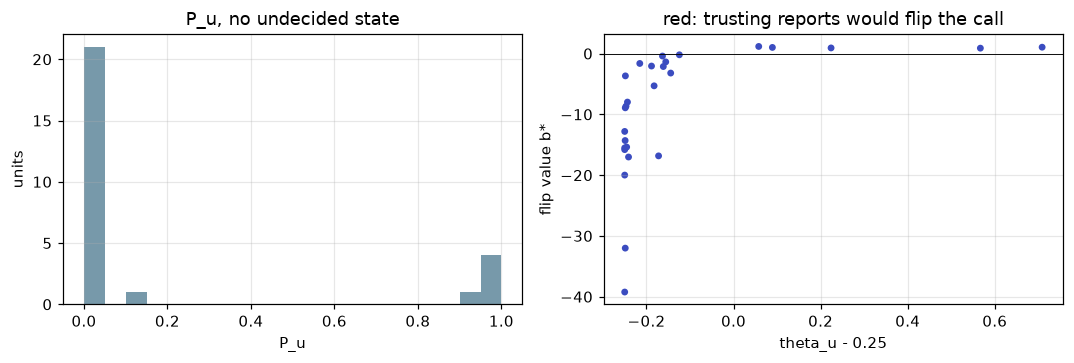

In [6]:
calls1 = K.make_calls(ours["theta"], ours["s"], TAU)
assert calls1["call"].shape == (va.U,) and np.all(np.isfinite(calls1["P"])), "every unit is answered"
rr = np.random.default_rng([SEED, 4])
rep = rr.random(va.n_plots) < 0.03 + 0.12 * va.y
claim = ((va.y > 0.5) | (rr.random(va.n_plots) < 0.10)).astype(float)
n_F = np.bincount(va.unit[rep], minlength=va.U)
rbar = np.bincount(va.unit[rep], weights=claim[rep], minlength=va.U) / np.maximum(n_F, 1)
fl = K.flip_value(ours["theta"], ours["s"], rbar, n_F, TAU)
truth_above = va.theta_true > TAU
has = n_F > 0
print(f"units with reports {has.mean():.2f}, median reports per unit {np.median(n_F[has]):.0f}")
print(f"mean report share {rbar[has].mean():.3f} vs mean true share {va.theta_true[has].mean():.3f}"
      f"  (true report bias {np.mean(rbar[has] - va.theta_true[has]):+.3f})")
print(f"wrong calls: official {np.mean(calls1['call'] != truth_above):.3f}; reports taken at face value "
      f"{np.mean(fl['call_c0'][has] != truth_above[has]):.3f}")
flipped = has & (fl["call_c0"] != calls1["call"])
print(f"units where trusting the reports would flip the call: {flipped.sum()}; median |b*| there {np.median(np.abs(fl['b_star'][flipped])) if flipped.any() else float('nan'):.3f}"
      f", elsewhere {np.median(np.abs(fl['b_star'][has & ~flipped])):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(calls1["P"], bins=20, color="#79a"); ax[0].set_xlabel("P_u"); ax[0].set_ylabel("units"); ax[0].set_title("P_u, no undecided state")
ax[1].scatter(ours["theta"][has] - TAU, fl["b_star"][has], c=flipped[has], cmap="coolwarm", s=12)
ax[1].axhline(0, color="k", lw=.6); ax[1].set_xlabel("theta_u - 0.25"); ax[1].set_ylabel("flip value b*")
ax[1].set_title("red: trusting reports would flip the call")
fig.tight_layout(); fig.savefig(OUT / "fig_calls_flip.png", dpi=130); plt.show()

## 5. Validation region: Monte Carlo over random check draws

The region is fixed; only the check draw changes (fixed seeds). Methods (all answer every unit):

* `map_only`: raw calibrated map mean, `s` = training-region map RMSE;
* `sample_only`: Hajek mean of the checked plots, map ignored, cluster-robust variance;
* `report_formula`: the partial report's Section 3.4 formula (stratum rate shrunk to `pi_h`, iid binomial
  variance, inclusion probabilities ignored);
* `ppi_v1`: the first version (shrink toward the training pool, treated as exact);
* `ppi_naive`: our estimator with inclusion probabilities ignored;
* `ppi_ipw`: our estimator (Hajek weights, shrinkage, cluster-robust variance); `ppi_ipw_iid` is the same
  estimate with the iid variance, to show what clustering does to coverage;
* `ppi_ht`: unshrunk Horvitz-Thompson form, the design-unbiased reference.

Metrics: bias (mean signed error), mean absolute per-unit bias, RMSE, coverage of the 90% interval,
wrong 25% calls, Brier score and expected calibration error (ECE) of `P_u`.

In [7]:
def table(res, truth, budgets, methods=E.METHODS):
    out = {m: {b: K.score(res[m][b]["theta"], res[m][b]["s"], truth, TAU) for b in budgets} for m in methods}
    return out

def show(tab, keys=("bias", "rmse", "cover90", "wrong", "ece"), budgets=None, methods=E.METHODS):
    budgets = budgets or list(next(iter(tab.values())).keys())
    for k in keys:
        print(f"\n{k:>16s} " + " ".join(f"{b:>7d}" for b in budgets))
        for m in methods:
            print(f"{m:>16s} " + " ".join(f"{tab[m][b][k]:7.3f}" for b in budgets))

t0 = time.time()
res_va, n_va = E.monte_carlo(va, hyp, BUDGETS, "random", REPS_VAL, seed=SEED + 10)
tab_va = table(res_va, va.theta_true, BUDGETS)
print(f"validation, random design, {REPS_VAL} draws per budget ({time.time() - t0:.0f} s); columns = checks per unit")
show(tab_va)

validation, random design, 120 draws per budget (4 s); columns = checks per unit

            bias       0       4       8      16      32      64
        map_only   0.009   0.009   0.009   0.009   0.009   0.009
     sample_only  -0.018  -0.001   0.003   0.003  -0.001   0.000
  report_formula  -0.048  -0.031  -0.022  -0.011  -0.006  -0.003
          ppi_v1  -0.051  -0.033  -0.023  -0.013  -0.008  -0.004
       ppi_naive  -0.051  -0.016  -0.007  -0.003  -0.002  -0.001
         ppi_ipw  -0.051  -0.015  -0.007  -0.003  -0.002  -0.001
     ppi_ipw_iid  -0.051  -0.015  -0.007  -0.003  -0.002  -0.001
          ppi_ht  -0.051  -0.004   0.002   0.004   0.002   0.001

            rmse       0       4       8      16      32      64
        map_only   0.082   0.082   0.082   0.082   0.082   0.082
     sample_only   0.250   0.186   0.134   0.095   0.048   0.018
  report_formula   0.108   0.087   0.070   0.049   0.029   0.017
          ppi_v1   0.105   0.085   0.068   0.047   0.028   0.016
       

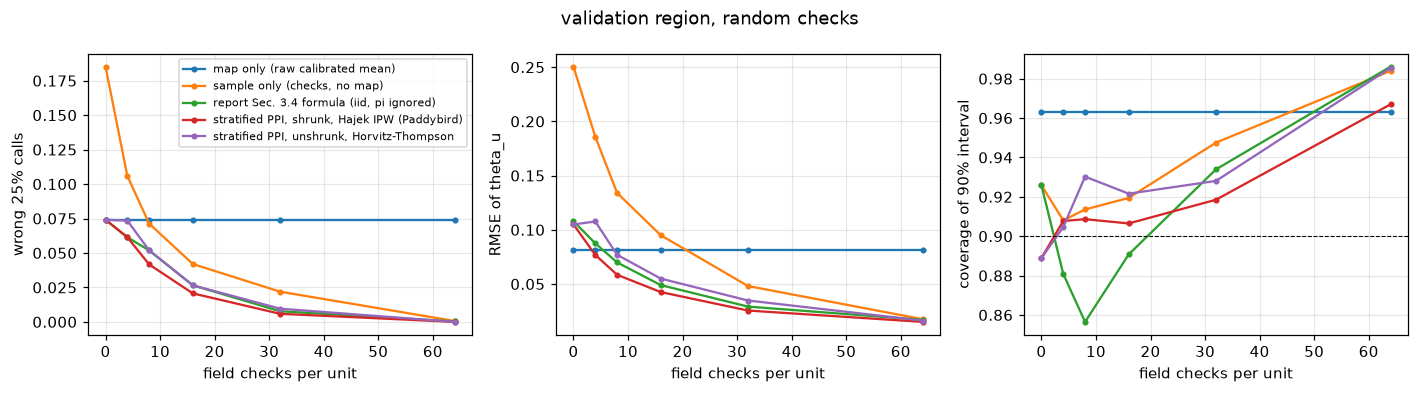

In [8]:
def plot_curves(tab, title, fname, methods=("map_only", "sample_only", "report_formula", "ppi_ipw", "ppi_ht")):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    for m in methods:
        b = list(tab[m].keys())
        for a, k in zip(ax, ("wrong", "rmse", "cover90")):
            a.plot(b, [tab[m][x][k] for x in b], "o-", ms=3, label=E.METHOD_LABELS[m])
    ax[0].set_ylabel("wrong 25% calls"); ax[1].set_ylabel("RMSE of theta_u"); ax[2].set_ylabel("coverage of 90% interval")
    ax[2].axhline(0.9, color="k", lw=.7, ls="--")
    for a in ax: a.set_xlabel("field checks per unit")
    ax[0].legend(fontsize=7); fig.suptitle(title); fig.tight_layout(); fig.savefig(OUT / fname, dpi=130); plt.show()

plot_curves(tab_va, "validation region, random checks", "fig_val_curves.png")

### Calibration of P_u (reliability curve)

Pooled over all draws and units at 16 checks per unit. A calibrated `P_u` lies on the diagonal: among
units given `P_u` near 0.7, about 70% are truly above the line.

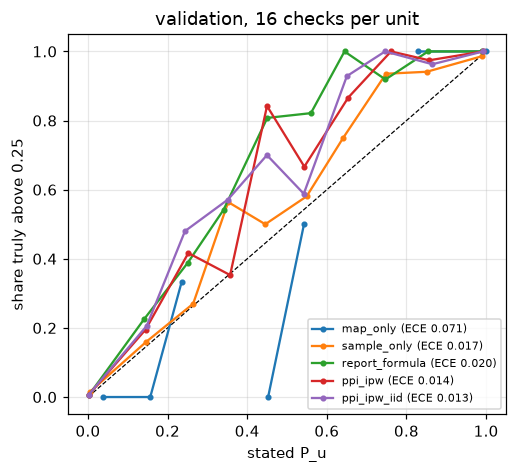

In [9]:
def plot_rel(res, truth, b, title, fname, methods=("map_only", "sample_only", "report_formula", "ppi_ipw", "ppi_ipw_iid")):
    fig, ax = plt.subplots(figsize=(4.8, 4.4))
    ax.plot([0, 1], [0, 1], "k--", lw=.8)
    rel = {}
    for m in methods:
        P = K.make_calls(res[m][b]["theta"], res[m][b]["s"], TAU)["P"]
        r = K.reliability(P, np.broadcast_to(truth > TAU, P.shape), n_bins=10)
        rel[m] = r
        ax.plot(r["mean_P"], r["freq"], "o-", ms=3, label=f"{m} (ECE {r['ece']:.3f})")
    ax.set_xlabel("stated P_u"); ax.set_ylabel("share truly above 0.25"); ax.legend(fontsize=7); ax.set_title(title)
    fig.tight_layout(); fig.savefig(OUT / fname, dpi=130); plt.show()
    return rel

rel_va = plot_rel(res_va, va.theta_true, B_SHOW, f"validation, {B_SHOW} checks per unit", "fig_val_reliability.png")

## 6. Stress test: route-style selection

Officers check what they can reach. Here a visit site is drawn with probability proportional to
`0.05 + exp(-road_km / 0.6)`, so near-road sites are drawn many times more often; the probability is
recorded with each check. Near-road plots are less flooded than the map says, so the unweighted
estimators are pulled down. The importance-weighted estimators use the recorded probabilities.

A second variant (`route + unreached`) drops drawn far sites with probability up to 0.5 (the day ran out)
while the estimator still uses the nominal probabilities: the case flagged in the partial report's Section
4.4, where nominal and realised probabilities differ.

The route stress test needs road distances, so with real inputs that lack them it runs on the synthetic
regions.

validation, ROUTE design

            bias       4       8      16      32      64
     sample_only  -0.021  -0.017  -0.010  -0.007  -0.003
  report_formula  -0.072  -0.059  -0.046  -0.037  -0.027
          ppi_v1  -0.089  -0.070  -0.049  -0.034  -0.022
       ppi_naive  -0.043  -0.036  -0.033  -0.029  -0.020
         ppi_ipw  -0.044  -0.031  -0.021  -0.014  -0.007
          ppi_ht   0.010   0.006   0.004   0.002   0.001

            rmse       4       8      16      32      64
     sample_only   0.117   0.107   0.086   0.062   0.047
  report_formula   0.102   0.086   0.066   0.051   0.038
          ppi_v1   0.114   0.094   0.071   0.052   0.038
       ppi_naive   0.077   0.066   0.054   0.043   0.032
         ppi_ipw   0.078   0.066   0.053   0.042   0.032
          ppi_ht   0.182   0.165   0.139   0.102   0.067

         cover90       4       8      16      32      64
     sample_only   0.898   0.874   0.842   0.843   0.888
  report_formula   0.928   0.923   0.934   0.942   0.972
   

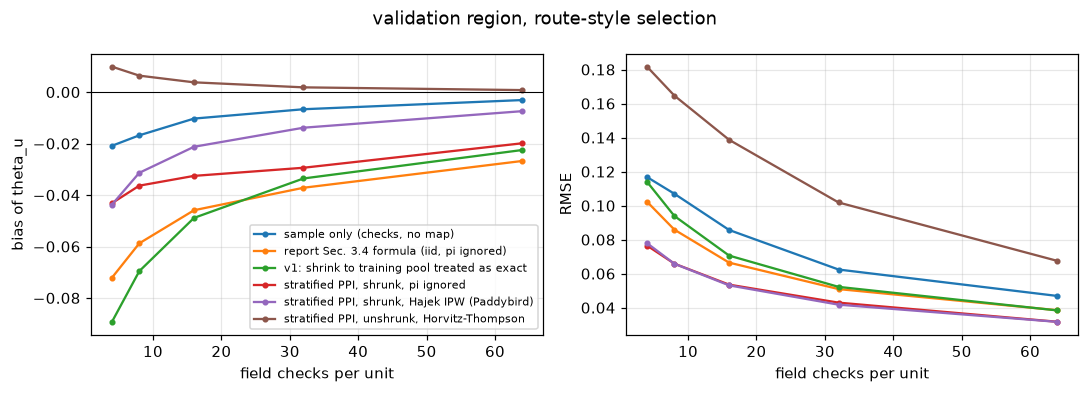

In [10]:
if va.site_road is None:
    px_r = E.synthetic_pixels(120, seed=SEED + 1, n_events=6); calib = px_r["calib"]
    mkr = lambda px: E.frame_from_pixels(px["unit"], px["plot"], px["prob"], px["site"], px["label"], px["road_km"], event=px["event"])
    tr_r = mkr(px_r); hyp_r = E.fit_hyper(tr_r, k=K_VISIT, seed=SEED); del px_r
    va_r = mkr(E.synthetic_pixels(120, seed=SEED + 2, flood_shift=0.3, calib=calib))
    te_r = mkr(E.synthetic_pixels(120, seed=SEED + 3, flood_shift=0.15, calib=calib))
else:
    hyp_r, va_r, te_r = hyp, va, te
ROUTE_M = ("sample_only", "report_formula", "ppi_v1", "ppi_naive", "ppi_ipw", "ppi_ht")
res_vr, _ = E.monte_carlo(va_r, hyp_r, BUDGETS[1:], "route", REPS_VAL, seed=SEED + 20)
tab_vr = table(res_vr, va_r.theta_true, BUDGETS[1:])
print("validation, ROUTE design")
show(tab_vr, keys=("bias", "rmse", "cover90", "wrong"), methods=ROUTE_M)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for m in ROUTE_M:
    b = BUDGETS[1:]
    ax[0].plot(b, [tab_vr[m][x]["bias"] for x in b], "o-", ms=3, label=E.METHOD_LABELS[m])
    ax[1].plot(b, [tab_vr[m][x]["rmse"] for x in b], "o-", ms=3)
ax[0].axhline(0, color="k", lw=.7); ax[0].set_ylabel("bias of theta_u"); ax[1].set_ylabel("RMSE")
for a in ax: a.set_xlabel("field checks per unit")
ax[0].legend(fontsize=7); fig.suptitle("validation region, route-style selection"); fig.tight_layout()
fig.savefig(OUT / "fig_val_route.png", dpi=130); plt.show()

## 7. TEST REGION (touched once)

Everything above was fixed before this cell: strata, `m`, `Rpool`, `T`, ICC and the methods. The cell
below runs the same Monte Carlo on the held-out test region, for random, route and route-with-unreached
designs, plus a between-region check: the headline metrics at 16 checks per unit on five more held-out
synthetic regions (new seeds), to show how much the numbers move from region to region. The numbers are
reported as they come out. As explained in Section 3, the test events were already seen once by v1; the
v1 first-run numbers are printed first.

In [11]:
# ===================== TEST: run once =====================
v1p = OUT / "test_first_run_v1.json"
if v1p.exists():
    v1 = json.loads(v1p.read_text())
    print("v1 FIRST TEST RUN (frozen record):", v1["input"])
    for k in ("wrong", "rmse", "cover90", "ece"):
        print(f"  {k:8s}", {m: [round(v1["design_random"][m][b][k], 3) for b in ("0", "16", "32")] for m in ("map_only", "ppi_ipw")}, "(budgets 0, 16, 32)")
t0 = time.time()
res_te, n_te = E.monte_carlo(te, hyp, BUDGETS, "random", REPS_TEST, seed=SEED + 100)
tab_te = table(res_te, te.theta_true, BUDGETS)
res_tr_, _ = E.monte_carlo(te_r, hyp_r, BUDGETS[1:], "route", REPS_TEST, seed=SEED + 200)
tab_tr_ = table(res_tr_, te_r.theta_true, BUDGETS[1:])
res_tu, _ = E.monte_carlo(te_r, hyp_r, BUDGETS[1:], "route", REPS_TEST, seed=SEED + 300, unreached=0.5)
tab_tu = table(res_tu, te_r.theta_true, BUDGETS[1:])
between = {m: [] for m in ("map_only", "sample_only", "ppi_ipw")}
for j in range(5):
    pxj = E.synthetic_pixels(120, seed=SEED + 40 + j, flood_shift=[-0.3, 0.0, 0.15, 0.3, 0.5][j], calib=calib)
    frj = E.frame_from_pixels(pxj["unit"], pxj["plot"], pxj["prob"], pxj["site"], pxj["label"], pxj["road_km"])
    rj, _ = E.monte_carlo(frj, hyp_r, [B_SHOW], "random", 60, seed=SEED + 500 + j)
    for m in between:
        between[m].append(K.score(rj[m][B_SHOW]["theta"], rj[m][B_SHOW]["s"], frj.theta_true, TAU))
print(f"test runs done in {time.time() - t0:.0f} s")
print("\nTEST, random design"); show(tab_te)
print("\nTEST, route design"); show(tab_tr_, keys=("bias", "rmse", "cover90", "wrong"), methods=ROUTE_M)
print("\nTEST, route design with unreached far sites (nominal pi)"); show(tab_tu, keys=("bias", "rmse", "cover90", "wrong"), methods=ROUTE_M)
print(f"\nfive more held-out regions, {B_SHOW} checks per unit, random design (min / mean / max):")
for m, v in between.items():
    for k in ("wrong", "rmse", "cover90", "ece"):
        a = np.array([x[k] for x in v]); print(f"  {m:12s} {k:8s} {a.min():.3f} / {a.mean():.3f} / {a.max():.3f}")

v1 FIRST TEST RUN (frozen record): real layer 2 artifacts (artifacts/layer2/maps (121 chips); units: layer 1 chip windows (121 chips))
  wrong    {'map_only': [0.147, 0.147, 0.147], 'ppi_ipw': [0.206, 0.103, 0.069]} (budgets 0, 16, 32)
  rmse     {'map_only': [0.16, 0.16, 0.16], 'ppi_ipw': [0.222, 0.082, 0.047]} (budgets 0, 16, 32)
  cover90  {'map_only': [0.824, 0.824, 0.824], 'ppi_ipw': [0.588, 0.739, 0.822]} (budgets 0, 16, 32)
  ece      {'map_only': [0.071, 0.071, 0.071], 'ppi_ipw': [0.196, 0.05, 0.017]} (budgets 0, 16, 32)


test runs done in 71 s

TEST, random design

            bias       0       4       8      16      32      64
        map_only  -0.077  -0.077  -0.077  -0.077  -0.077  -0.077
     sample_only  -0.093  -0.035  -0.017  -0.004  -0.000   0.000
  report_formula  -0.138  -0.086  -0.060  -0.036  -0.021  -0.014
          ppi_v1  -0.148  -0.092  -0.063  -0.035  -0.018  -0.008
       ppi_naive  -0.148  -0.043  -0.021  -0.008  -0.004  -0.001
         ppi_ipw  -0.148  -0.042  -0.020  -0.007  -0.002   0.000
     ppi_ipw_iid  -0.148  -0.042  -0.020  -0.007  -0.002   0.000
          ppi_ht  -0.148  -0.004   0.003   0.002   0.001   0.001

            rmse       0       4       8      16      32      64
        map_only   0.160   0.160   0.160   0.160   0.160   0.160
     sample_only   0.260   0.202   0.158   0.105   0.057   0.024
  report_formula   0.213   0.159   0.123   0.081   0.050   0.032
          ppi_v1   0.222   0.164   0.127   0.082   0.047   0.023
       ppi_naive   0.222   0.123   0.095   0

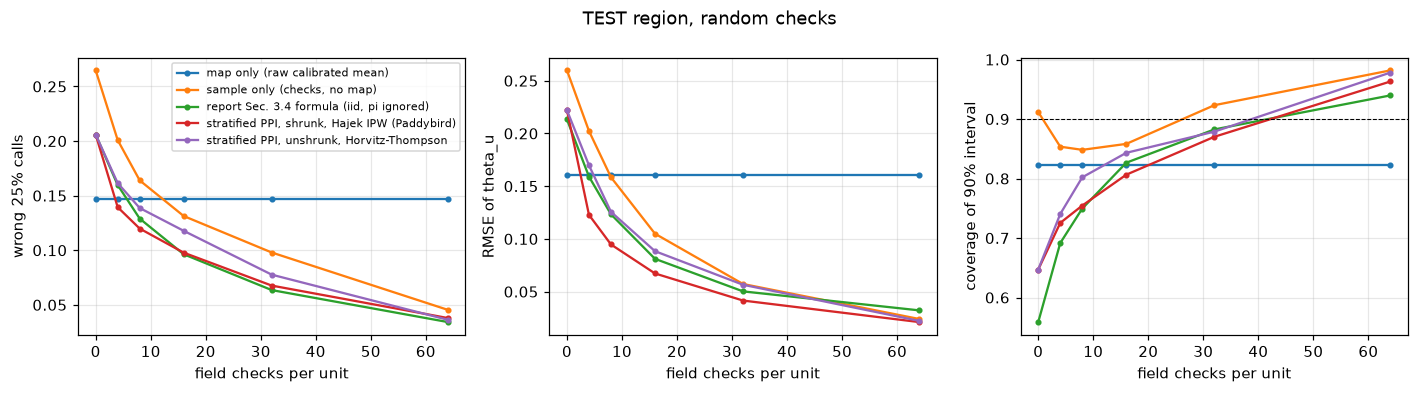

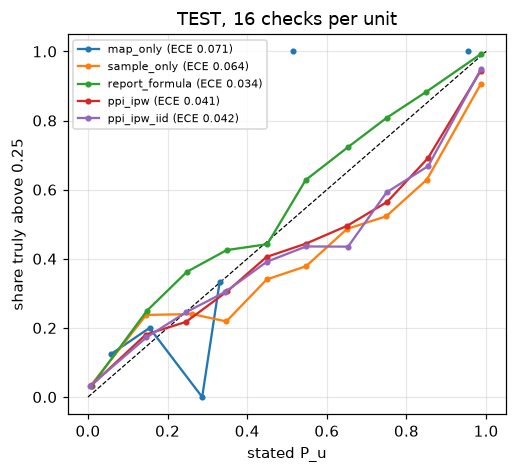

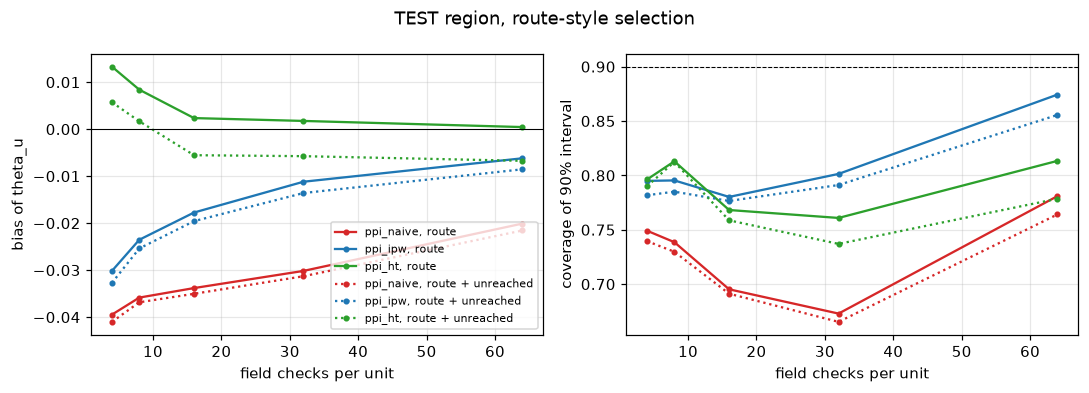

In [12]:
plot_curves(tab_te, "TEST region, random checks", "fig_test_curves.png")
rel_te = plot_rel(res_te, te.theta_true, B_SHOW, f"TEST, {B_SHOW} checks per unit", "fig_test_reliability.png")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for tab_, ls, nm in ((tab_tr_, "-", "route"), (tab_tu, ":", "route + unreached")):
    for m, col in (("ppi_naive", "C3"), ("ppi_ipw", "C0"), ("ppi_ht", "C2")):
        b = BUDGETS[1:]
        ax[0].plot(b, [tab_[m][x]["bias"] for x in b], ls, color=col, marker="o", ms=3, label=f"{m}, {nm}")
        ax[1].plot(b, [tab_[m][x]["cover90"] for x in b], ls, color=col, marker="o", ms=3)
ax[0].axhline(0, color="k", lw=.7); ax[1].axhline(.9, color="k", lw=.7, ls="--")
ax[0].set_ylabel("bias of theta_u"); ax[1].set_ylabel("coverage of 90% interval")
for a in ax: a.set_xlabel("field checks per unit")
ax[0].legend(fontsize=7); fig.suptitle("TEST region, route-style selection"); fig.tight_layout()
fig.savefig(OUT / "fig_test_route.png", dpi=130); plt.show()

## 8. What the numbers say about the partial report

The cell below prints the comparisons that bear on claims in the partial report (Sections 3.4, 4.1 and
4.4). They are computed, not written in by hand, so the text in the summary at the end can be checked
against them.

In [13]:
b_lo = [b for b in BUDGETS if 0 < b <= 8]
claims = {}
claims["checks_worse_than_map_at_small_budget"] = {b: bool(tab_te["ppi_ipw"][b]["wrong"] > tab_te["map_only"][b]["wrong"]) for b in b_lo}
claims["report_formula_cover90_test_16"] = tab_te["report_formula"][16]["cover90"]
claims["report_formula_ece_test_16"] = tab_te["report_formula"][16]["ece"]
claims["ppi_ipw_cover90_test_16"] = tab_te["ppi_ipw"][16]["cover90"]
claims["iid_variance_cover90_test_16"] = tab_te["ppi_ipw_iid"][16]["cover90"]
claims["ppi_v1_cover90_test_16"] = tab_te["ppi_v1"][16]["cover90"]
claims["route_bias_naive_test_32"] = tab_tr_["ppi_naive"][32]["bias"]
claims["route_bias_hajek_test_32"] = tab_tr_["ppi_ipw"][32]["bias"]
claims["route_bias_ht_test_32"] = tab_tr_["ppi_ht"][32]["bias"]
claims["route_unreached_bias_ht_test_32"] = tab_tu["ppi_ht"][32]["bias"]
claims["route_wrong_naive_vs_ipw_test_32"] = (tab_tr_["ppi_naive"][32]["wrong"], tab_tr_["ppi_ipw"][32]["wrong"])
claims["map_only_wrong_test"] = tab_te["map_only"][0]["wrong"]
claims["ppi_ipw_wrong_test_32"] = tab_te["ppi_ipw"][32]["wrong"]
claims["sample_only_wrong_test_32"] = tab_te["sample_only"][32]["wrong"]
for k, v in claims.items():
    print(f"{k:42s} {v}")

checks_worse_than_map_at_small_budget      {4: False, 8: False}
report_formula_cover90_test_16             0.8266176470588236
report_formula_ece_test_16                 0.03361207357527432
ppi_ipw_cover90_test_16                    0.8064705882352942
iid_variance_cover90_test_16               0.7604411764705883
ppi_v1_cover90_test_16                     0.7264705882352941
route_bias_naive_test_32                   -0.030161784514990936
route_bias_hajek_test_32                   -0.011184729431187689
route_bias_ht_test_32                      0.001749638538026824
route_unreached_bias_ht_test_32            -0.005748466651894021
route_wrong_naive_vs_ipw_test_32           (0.09295833333333334, 0.07683333333333334)
map_only_wrong_test                        0.14705882352941177
ppi_ipw_wrong_test_32                      0.06764705882352941
sample_only_wrong_test_32                  0.09794117647058824


## 9. Artifacts

* `unit_calls.csv`: the state layer 4 and 5 start from **today**, before any field checks: `theta_u` is the
  map plus the training-region correction, `s_u` its error, the call and `P_u`, `n_checks = 0`. The raw map
  share and its `P` are added as `theta_map_raw`, `P_map_raw`, because with zero checks the training
  correction did not beat the raw map on either validation region (see the budget-0 column above).
* `unit_calls_simulated_checks.csv`: the same table after one simulated draw of 16 checks per unit
  (fixed seed), with the farmer-report flip value. Labelled simulated; there are no real field checks yet.
* `unit_strata.npz`: per unit-stratum `W_uh`, `Fbar_uh`, checks `n_uh`, shrink weight `lam_uh` and
  corrected rectifier `Rt_uh`, for layer 4's allocation.
* `hyper.json`: `tau`, strata cuts, `m`, `Rpool`, `T`, `pi_h` (3 strata) and `pi_h_2` (2 strata at 0.5, the
  "mapped dry / mapped flooded" split layer 4 uses), ICC, design effect.
* `validation.json`, `test.json`: every metric table; `reliability.json`; figures; `MANIFEST.json`.
* `test_first_run_v1.json`: frozen record of v1's first test run (not regenerated by this notebook).

In [14]:
def jdump(name, obj):
    (OUT / name).write_text(json.dumps(obj, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o)))

def write_calls(name, fr, est, n, extra=None):
    c = K.make_calls(est["theta"], est["s"], TAU)
    cols = ["unit_id", "region", "theta", "s", "call", "P_u", "P_right", "n_checks", "n_sites"] + list((extra or {}).keys())
    with open(OUT / name, "w", newline="") as fh:
        w = csv.writer(fh); w.writerow(cols)
        for u in range(fr.U):
            row = [fr.unit_ids[u], "test", f"{est['theta'][u]:.5f}", f"{est['s'][u]:.5f}", "above" if c["call"][u] else "below",
                   f"{c['P'][u]:.5f}", f"{c['P_right'][u]:.5f}", int(n[u]), int(est.get("n_sites", np.zeros(fr.U))[u])]
            row += [("" if not np.isfinite(v[u]) else f"{v[u]:.5f}") for v in (extra or {}).values()]
            w.writerow(row)
    return c

empty = dict(idx=np.zeros(0, int), pi=np.zeros(0), site=np.zeros(0, int))
est0 = E.est_ppi(te, empty, hyp)
c_map = K.make_calls(te.theta_map, np.full(te.U, hyp.map_rmse), TAU)
c0 = write_calls("unit_calls.csv", te, est0, np.zeros(te.U, int),
                 dict(theta_map_raw=te.theta_map, P_map_raw=c_map["P"]))
chk_t = E.draw_checks(te, B_SHOW, np.random.default_rng([SEED, 7]), "random", K_VISIT)
est16 = E.est_ppi(te, chk_t, hyp)
rt = np.random.default_rng([SEED, 8])
rep_t = rt.random(te.n_plots) < 0.03 + 0.12 * te.y
claim_t = ((te.y > 0.5) | (rt.random(te.n_plots) < 0.10)).astype(float)
nF_t = np.bincount(te.unit[rep_t], minlength=te.U)
rbar_t = np.where(nF_t > 0, np.bincount(te.unit[rep_t], weights=claim_t[rep_t], minlength=te.U) / np.maximum(nF_t, 1), np.nan)
fl_t = K.flip_value(est16["theta"], est16["s"], rbar_t, nF_t, TAU)
c16 = write_calls("unit_calls_simulated_checks.csv", te, est16, est16["n"],
                  dict(farmer_reports=nF_t.astype(float), report_share=rbar_t, flip_b=fl_t["b_star"], theta_if_reports_trusted=fl_t["theta_c0"]))
np.savez_compressed(OUT / "unit_strata.npz", unit_id=te.unit_ids.astype(str), **E.unit_strata_table(te, est16),
                    W_uh_n0=te.W_uh, strata=np.array(["mapped_dry", "uncertain", "mapped_flooded"]))
f2 = tr.f >= 0.5
pi_h_2 = [float(np.sum(tr.w[~f2] * tr.y[~f2]) / tr.w[~f2].sum()), float(np.sum(tr.w[f2] * tr.y[f2]) / tr.w[f2].sum())]
hj = json.loads(hyp.to_json()); hj.update(estimator_version="v2 (event-level prior, region pooling)", tau=TAU, pi_h_2=pi_h_2, pi_h_2_cut=0.5, strata=["mapped_dry", "uncertain", "mapped_flooded"])
jdump("hyper.json", hj)

def tabjson(tab):
    return {m: {str(b): v for b, v in d.items()} for m, d in tab.items()}
jdump("validation.json", dict(design_random=tabjson(tab_va), design_route=tabjson(tab_vr), reps=REPS_VAL, budgets=BUDGETS))
jdump("test.json", dict(design_random=tabjson(tab_te), design_route=tabjson(tab_tr_), design_route_unreached=tabjson(tab_tu),
                        between_regions_b16={m: v for m, v in between.items()}, reps=REPS_TEST, budgets=BUDGETS, claims=claims))
jdump("reliability.json", dict(budget=B_SHOW, validation={m: {k: v for k, v in r.items()} for m, r in rel_va.items()},
                               test={m: {k: v for k, v in r.items()} for m, r in rel_te.items()}))
print("today (no checks): units above", int(c0["call"].sum()), "of", te.U, "; after simulated 16 checks:", int(c16["call"].sum()))

today (no checks): units above 2 of 34 ; after simulated 16 checks: 9


In [15]:
code = {p.name: sha(p) for p in sorted((ROOT / "paddybird").glob("*.py")) if p.name in ("estimator.py", "calls.py", "variance.py")}
files = {}
for p in sorted(OUT.iterdir()):
    if p.name == "MANIFEST.json" or p.is_dir():
        continue
    files[p.name] = dict(sha256_16=sha(p), bytes=p.stat().st_size)
schema = {
    "unit_calls.csv": "unit_id, region, theta (flooded paddy share), s (std error), call (above|below, never undecided), P_u = Phi((theta-0.25)/s), P_right, n_checks, n_sites, theta_map_raw, P_map_raw; state before any field check",
    "unit_calls_simulated_checks.csv": "as unit_calls.csv after one SIMULATED draw of 16 checks per unit, plus farmer_reports, report_share, flip_b, theta_if_reports_trusted",
    "unit_strata.npz": "per unit (rows) and stratum (cols: mapped_dry, uncertain, mapped_flooded): W_uh, Fbar_uh, n_uh, lam_uh, Rt_uh; W_uh_n0; unit_id",
    "hyper.json": "tau, cuts, m, Rpool, T, sigma2, icc, deff, pi_h, pi_h_2 (2 strata at 0.5), map_rmse, m_grid_rmse (fitted on the training region only)",
    "validation.json": "metric tables [method][budget] on the validation region, random and route designs",
    "test.json": "metric tables on the test region (random, route, route_unreached), between-region spread, report-claim checks",
    "reliability.json": "reliability curves of P_u at budget 16",
    "test_first_run_v1.json": "frozen record of the first clean test run of estimator v1 (real layer 2 maps); not regenerated",
}
manifest = dict(layer=3, notebook="03_estimation.ipynb", created=time.strftime("%Y-%m-%d"), seed=SEED, input=INPUT,
                input_sources=SRC_HASH, tau=TAU, plots_per_visit=K_VISIT, budgets=BUDGETS,
                reps=dict(validation=REPS_VAL, test=REPS_TEST), units=dict(train=tr.U, val=va.U, test=te.U),
                shapes={"unit_calls.csv": [te.U, 11], "unit_strata.npz/W_uh": list(te.W_uh.shape)},
                schema=schema, files=files, code_sha256_16=code,
                versions=dict(python=platform.python_version(), numpy=np.__version__, matplotlib=matplotlib.__version__),
                notes="Synthetic unless input says real. Checks in unit_calls_simulated_checks.csv are simulated. No abstain state.")
(OUT / "MANIFEST.json").write_text(json.dumps(manifest, indent=1))
print(json.dumps({k: manifest[k] for k in ("input", "seed", "units", "reps")}, indent=1)); print(len(files), "files")

{
 "input": "real layer 2 artifacts (artifacts/layer2/maps (121 chips); units: layer 1 chip windows (121 chips))",
 "seed": 20261118,
 "units": {
  "train": 125,
  "val": 27,
  "test": 34
 },
 "reps": {
  "validation": 120,
  "test": 200
 }
}
18 files


## 10. Closing assertions

Bounds stated before the test run: on the test region with random checks, (a) at 32 checks per unit the
Paddybird estimator makes fewer wrong calls than the map alone and than checks alone; (b) its 90% interval
covers between 80% and 97% of the time at 16 and 32 checks; (c) the ECE of `P_u` at 16 checks is below
0.06; (d) under route selection the Horvitz-Thompson form has absolute bias below 0.005 at 32 checks
while the unweighted form is biased by more than twice that; (e) every unit is answered.

In [16]:
T_ = tab_te
assert T_["ppi_ipw"][32]["wrong"] < T_["map_only"][32]["wrong"], "(a) beats map"
assert T_["ppi_ipw"][32]["wrong"] < T_["sample_only"][32]["wrong"], "(a) beats sample only"
for b in (16, 32):
    assert 0.80 <= T_["ppi_ipw"][b]["cover90"] <= 0.97, f"(b) coverage at {b}: {T_['ppi_ipw'][b]['cover90']:.3f}"
assert T_["ppi_ipw"][16]["ece"] < 0.06, "(c) calibration"
assert abs(tab_tr_["ppi_ht"][32]["bias"]) < 0.005, "(d) HT unbiased under route"
assert abs(tab_tr_["ppi_naive"][32]["bias"]) > 2 * abs(tab_tr_["ppi_ht"][32]["bias"]), "(d) naive is biased"
assert len(c0["call"]) == te.U and len(c16["call"]) == te.U, "(e) every unit answered"
print("all layer 3 assertions passed")

all layer 3 assertions passed
